# Анализ взыскания задолженности за ЖКУ и претензионно-исковой работы управляющей компании

**Автор:** Павлов Юрий Николаевич  
**Инструменты:** Python (pandas, NumPy, matplotlib, seaborn), SQL (SQLite)

> **Статус данных.** В репозитории используются **смоделированные данные**: реальные дела закрыты адвокатской и коммерческой тайной, а также законодательством о персональных данных. Параметры модели заданы в явном виде в разделе «Допущения». Ноутбук построен так, чтобы без изменения кода работать на **обезличенном реестре** (файл `data/claims_register.csv`, схема описана ниже): тогда все показатели, графики и выводы пересчитываются автоматически.

---

## Практическая задача

Управляющая компания ведёт реестр задолженности за жилищно-коммунальные услуги. По нему нужно регулярно отвечать на вопросы, от которых зависит порядок работы юриста:

1. Какова воронка взыскания: претензия → судебный приказ → отмена приказа → иск → исполнительное производство?
2. Какая доля долга реально возвращается и как это зависит от типа платежа и возраста долга?
3. Сколько времени занимает каждый путь взыскания?
4. Какая часть портфеля находится под риском истечения срока исковой давности (3 года, ст. 196 ГК РФ)?
5. В каком порядке подавать заявления, если возможности ограничены (ожидаемая отдача по группам дел)?

**Результат:** воспроизводимый отчёт по реестру с доверительными интервалами и SQL-запросами к тем же данным.

## 1. Подготовка и параметры

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

warnings.simplefilter('default')            # предупреждения не скрываются
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams['figure.figsize'] = (11, 5)
sns.set_style('whitegrid')

ANALYSIS_YEAR = 2026                        # фиксированный год: результаты воспроизводимы
SEED = 99
DATA_PATH = 'data/claims_register.csv'      # сюда кладётся обезличенный реестр
SAMPLE_PATH = 'data/sample_claims_register_synthetic.csv'
os.makedirs('data', exist_ok=True)

## 2. Схема данных и допущения модели

**Схема реестра** (одна строка - одно дело о взыскании; обезличенный реестр должен содержать те же столбцы):

| Столбец | Тип | Описание |
|---|---|---|
| `тип_долга` | текст | коммунальные услуги / содержание жилого помещения / взносы на капитальный ремонт |
| `год_подачи` | число | год начала взыскания |
| `сумма_долга` | число | заявленный основной долг, руб. |
| `возраст_долга_мес` | число | возраст долга на дату подачи, мес. |
| `оплачено_после_претензии` | 0/1 | должник оплатил после претензии |
| `приказ_выдан` | 0/1 | судебный приказ выдан |
| `приказ_отменён` | 0/1 | приказ отменён по возражениям должника |
| `иск_подан` | 0/1 | подан иск (после отмены или отказа в приказе) |
| `иск_удовлетворён` | 0/1 | иск удовлетворён полностью или в части |
| `на_исполнении` | 0/1 | дело передано на исполнение |
| `взыскано` | число | фактически взысканная сумма, руб. |
| `срок_дней` | число | срок от претензии до завершения, дн. |

**Обезличивание.** Перед загрузкой реальных данных исключаются ФИО, адреса, номера лицевых счетов и иные персональные данные, а также сведения, составляющие адвокатскую или коммерческую тайну.

**Допущения генератора** (используются только для смоделированных данных; значения ориентировочные и не являются статистикой):

In [2]:
ASSUMPTIONS = {
    # вероятность оплаты после претензии (базовая; снижается с возрастом долга)
    'pay_after_claim': {'коммунальные услуги': 0.24, 'содержание жилого помещения': 0.22,
                        'взносы на капитальный ремонт': 0.16},
    'age_penalty_pay': 0.002,        # снижение вероятности оплаты на 0,2 п.п. за месяц возраста долга
    'order_issued': 0.94,            # вероятность выдачи приказа
    'order_cancelled': {'коммунальные услуги': 0.16, 'содержание жилого помещения': 0.18,
                        'взносы на капитальный ремонт': 0.22},
    'claim_granted': 0.86,           # вероятность удовлетворения иска (полностью или в части)
    'exec_success': {'коммунальные услуги': 0.62, 'содержание жилого помещения': 0.58,
                     'взносы на капитальный ремонт': 0.52},
    'age_penalty_exec': 0.008,       # снижение результативности исполнения за месяц возраста долга
    'recovered_share_range': (0.40, 1.00),   # доля взысканного при успешном исполнении
    'limitation_months': 36,         # срок исковой давности (ст. 196 ГК РФ)
}
scalar = pd.Series({k: v for k, v in ASSUMPTIONS.items() if not isinstance(v, dict)}, name='значение').to_frame()
by_type_assump = pd.DataFrame({k: v for k, v in ASSUMPTIONS.items() if isinstance(v, dict)})
display(scalar)
display(by_type_assump)

,значение
age_penalty_pay,0.00
order_issued,0.94
claim_granted,0.86
age_penalty_exec,0.01
recovered_share_range,"(0.4, 1.0)"
limitation_months,36


,pay_after_claim,order_cancelled,exec_success
коммунальные услуги,0.24,0.16,0.62
содержание жилого помещения,0.22,0.18,0.58
взносы на капитальный ремонт,0.16,0.22,0.52


## 3. Загрузка данных
Если в папке `data/` есть файл `claims_register.csv`, анализируется он. Иначе генерируется смоделированный реестр на 320 дел с суммами требований до 100 тыс. руб. на дело.

In [3]:
REQUIRED = ['тип_долга', 'год_подачи', 'сумма_долга', 'возраст_долга_мес', 'оплачено_после_претензии',
            'приказ_выдан', 'приказ_отменён', 'иск_подан', 'иск_удовлетворён', 'на_исполнении',
            'взыскано', 'срок_дней']

def generate_register(n=320, seed=SEED, a=ASSUMPTIONS):
    rng = np.random.default_rng(seed)
    types = ['коммунальные услуги', 'содержание жилого помещения', 'взносы на капитальный ремонт']
    rows = []
    for _ in range(n):
        t = rng.choice(types, p=[0.50, 0.35, 0.15])
        amount = float(np.clip(rng.lognormal(mean=10.3, sigma=0.75), 5_000, 100_000))
        age = int(rng.integers(3, 43))
        year = int(rng.integers(ANALYSIS_YEAR - 4, ANALYSIS_YEAR + 1))
        eff = amount * (1 - max(0, age - a['limitation_months']) / age)   # часть, не утратившая силу по давности
        days = int(rng.integers(14, 31))                                    # претензионный этап
        paid = rng.random() < max(0.02, a['pay_after_claim'][t] - a['age_penalty_pay'] * age)
        issued = cancelled = suit = granted = on_exec = 0
        recovered = 0.0
        if paid:
            recovered = eff
        else:
            days += int(rng.integers(10, 46))                               # приказное производство
            issued = int(rng.random() < a['order_issued'])
            if issued:
                cancelled = int(rng.random() < a['order_cancelled'][t])
            suit = int((not issued) or cancelled)
            if suit:
                days += int(rng.integers(60, 181))                          # исковое производство
                granted = int(rng.random() < a['claim_granted'])
            on_exec = int((issued and not cancelled) or granted)
            if on_exec:
                days += int(rng.integers(60, 301))                          # исполнительное производство
                p_exec = max(0.05, a['exec_success'][t] - a['age_penalty_exec'] * age)
                if rng.random() < p_exec:
                    lo, hi = a['recovered_share_range']
                    recovered = eff * rng.uniform(lo, hi)
        rows.append(dict(тип_долга=t, год_подачи=year, сумма_долга=round(amount, -2),
                         возраст_долга_мес=age, оплачено_после_претензии=int(paid),
                         приказ_выдан=issued, приказ_отменён=cancelled, иск_подан=suit,
                         иск_удовлетворён=granted, на_исполнении=on_exec,
                         взыскано=round(recovered, -2), срок_дней=days))
    return pd.DataFrame(rows)

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    missing = [c for c in REQUIRED if c not in df.columns]
    assert not missing, f'В файле отсутствуют столбцы: {missing}'
    IS_SYNTHETIC = False
else:
    df = generate_register()
    df.to_csv(SAMPLE_PATH, index=False)
    IS_SYNTHETIC = True

DATA_LABEL = 'СМОДЕЛИРОВАННЫЕ ДАННЫЕ' if IS_SYNTHETIC else 'ОБЕЗЛИЧЕННЫЙ РЕЕСТР'
print(f'Источник данных: {DATA_LABEL}')
print(f'Дел в выборке: {len(df)}')
df.head()

Источник данных: СМОДЕЛИРОВАННЫЕ ДАННЫЕ
Дел в выборке: 320


,тип_долга,год_подачи,сумма_долга,возраст_долга_мес,оплачено_после_претензии,приказ_выдан,приказ_отменён,иск_подан,иск_удовлетворён,на_исполнении,взыскано,срок_дней
0,содержание жилого помещения,2024,"21,000.00",10,0,1,0,0,0,1,"16,100.00",365
1,взносы на капитальный ремонт,2025,"75,600.00",25,0,1,0,0,0,1,0.00,178
2,содержание жилого помещения,2023,"21,200.00",6,0,1,0,0,0,1,0.00,186
3,содержание жилого помещения,2022,"34,000.00",27,0,1,1,1,1,1,0.00,231
4,коммунальные услуги,2024,"52,900.00",14,0,1,0,0,0,1,0.00,190


## 4. Проверка качества данных
Перед расчётами проверяются пропуски, дубликаты и логическая согласованность статусов. Нарушения логики означают ошибки учёта, которые необходимо исправить в реестре.

In [4]:
df['сумма_к_взысканию'] = df['сумма_долга'] * (1 - (df['возраст_долга_мес'] - ASSUMPTIONS['limitation_months']).clip(lower=0) / df['возраст_долга_мес'])
df['утрачено_по_давности'] = df['сумма_долга'] - df['сумма_к_взысканию']
df['возрастная_группа'] = pd.cut(df['возраст_долга_мес'], [0, 12, 24, 36, 120],
                                 labels=['до 12 мес.', '12-24 мес.', '24-36 мес.', 'свыше 36 мес.'])
df['взыскано_флаг'] = (df['взыскано'] > 0).astype(int)

checks = {
    'пропуски (всего ячеек)': int(df[REQUIRED].isna().sum().sum()),
    'полные дубликаты строк': int(df.duplicated().sum()),
    'взыскано больше суммы долга': int((df['взыскано'] > df['сумма_долга'] + 1).sum()),
    'приказ отменён без выдачи приказа': int(((df['приказ_отменён'] == 1) & (df['приказ_выдан'] == 0)).sum()),
    'на исполнении без основания (ни приказа, ни решения)': int(((df['на_исполнении'] == 1) &
        ~(((df['приказ_выдан'] == 1) & (df['приказ_отменён'] == 0)) | (df['иск_удовлетворён'] == 1))).sum()),
    'оплачено после претензии, но есть судебные этапы': int(((df['оплачено_после_претензии'] == 1) &
        ((df['приказ_выдан'] == 1) | (df['иск_подан'] == 1))).sum()),
}
pd.Series(checks, name='количество').to_frame()

,количество
пропуски (всего ячеек),0
полные дубликаты строк,0
взыскано больше суммы долга,0
приказ отменён без выдачи приказа,0
"на исполнении без основания (ни приказа, ни решения)",0
"оплачено после претензии, но есть судебные этапы",0


## 5. Воронка взыскания
Для каждого перехода рассчитана доля и 95%-й доверительный интервал Уилсона: при малых выборках это защищает от переоценки результата.

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan, np.nan)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, c - h, c + h

N = len(df)
not_paid = df[df['оплачено_после_претензии'] == 0]
issued = not_paid[not_paid['приказ_выдан'] == 1]
suit = df[df['иск_подан'] == 1]
on_exec = df[df['на_исполнении'] == 1]

steps = [
    ('Оплата после претензии',            int(df['оплачено_после_претензии'].sum()), N),
    ('Приказ выдан (из неоплативших)',    len(issued), len(not_paid)),
    ('Приказ отменён (из выданных)',      int(issued['приказ_отменён'].sum()), len(issued)),
    ('Иск удовлетворён (из поданных)',    int(suit['иск_удовлетворён'].sum()), len(suit)),
    ('Взыскание состоялось (из дел на исполнении)', int(on_exec['взыскано_флаг'].sum()), len(on_exec)),
]
funnel = pd.DataFrame([(s, k, n, *wilson(k, n)) for s, k, n in steps],
                      columns=['переход', 'k', 'n', 'доля', 'ДИ_нижн', 'ДИ_верх'])
funnel_view = funnel.copy()
for c in ['доля', 'ДИ_нижн', 'ДИ_верх']:
    funnel_view[c] = (funnel_view[c] * 100).round(1).astype(str) + ' %'
funnel_view

,переход,k,n,доля,ДИ_нижн,ДИ_верх
0,Оплата после претензии,59,320,18.4 %,14.6 %,23.1 %
1,Приказ выдан (из неоплативших),242,261,92.7 %,88.9 %,95.3 %
2,Приказ отменён (из выданных),44,242,18.2 %,13.8 %,23.5 %
3,Иск удовлетворён (из поданных),51,63,81.0 %,69.6 %,88.8 %
4,Взыскание состоялось (из дел на исполнении),101,249,40.6 %,34.7 %,46.8 %


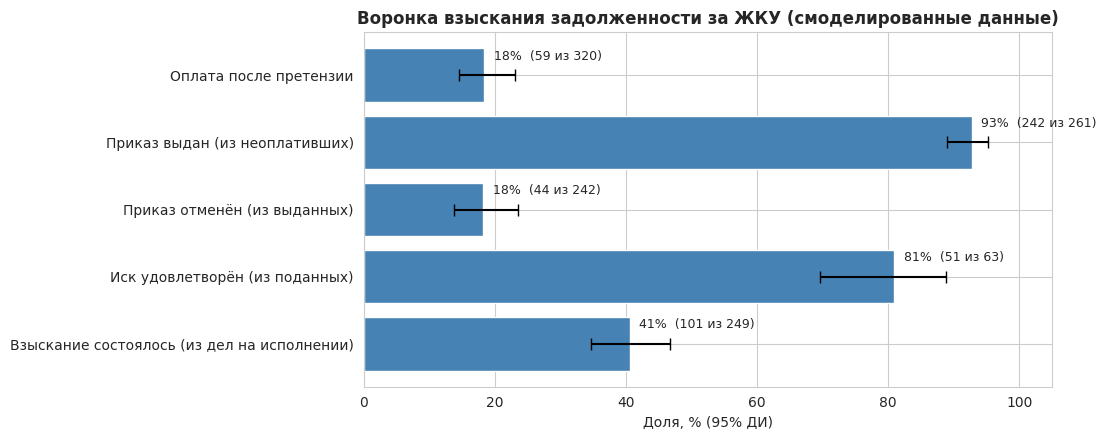

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(funnel))[::-1]
ax.barh(y, funnel['доля'] * 100, color='steelblue', edgecolor='white')
ax.errorbar(funnel['доля'] * 100, y,
            xerr=[(funnel['доля'] - funnel['ДИ_нижн']) * 100, (funnel['ДИ_верх'] - funnel['доля']) * 100],
            fmt='none', ecolor='black', capsize=4)
ax.set_yticks(y); ax.set_yticklabels(funnel['переход'])
ax.set_xlim(0, 105); ax.set_xlabel('Доля, % (95% ДИ)')
ax.set_title(f'Воронка взыскания задолженности за ЖКУ ({DATA_LABEL.lower()})', fontweight='bold')
for yi, v, k, n in zip(y, funnel['доля'] * 100, funnel['k'], funnel['n']):
    ax.text(v + 1.5, yi + 0.28, f'{v:.0f}%  ({k} из {n})', va='center', fontsize=9)
plt.tight_layout(); plt.show()

## 6. Взыскиваемость по типам долга и возрасту долга
Показатель **взыскиваемости** = взысканная сумма / сумма, не утратившая силу по давности. Показатель по делам - доля дел, по которым что-либо взыскано.

In [7]:
def group_report(by):
    g = df.groupby(by, observed=True)
    out = g.agg(дел=('взыскано', 'size'),
                сумма_к_взысканию=('сумма_к_взысканию', 'sum'),
                взыскано=('взыскано', 'sum'),
                дел_с_взысканием=('взыскано_флаг', 'sum'))
    out['взыскиваемость_по_сумме_%'] = out['взыскано'] / out['сумма_к_взысканию'] * 100
    ci = [wilson(k, n) for k, n in zip(out['дел_с_взысканием'], out['дел'])]
    out['доля_дел_с_взысканием_%'] = [c[0] * 100 for c in ci]
    out['ДИ_нижн_%'] = [c[1] * 100 for c in ci]
    out['ДИ_верх_%'] = [c[2] * 100 for c in ci]
    return out

by_type = group_report('тип_долга')
by_age = group_report('возрастная_группа')
display(by_type.round(1))
display(by_age.round(1))

,дел,сумма_к_взысканию,взыскано,дел_с_взысканием,взыскиваемость_по_сумме_%,доля_дел_с_взысканием_%,ДИ_нижн_%,ДИ_верх_%
тип_долга,,,,,,,,
взносы на капитальный ремонт,40,"1,498,537.40","377,200.00",16,25.20,40.00,26.30,55.40
коммунальные услуги,155,"6,232,824.10","2,761,200.00",81,44.30,52.30,44.40,60.00
содержание жилого помещения,125,"4,290,118.00","1,695,600.00",63,39.50,50.40,41.80,59.00


,дел,сумма_к_взысканию,взыскано,дел_с_взысканием,взыскиваемость_по_сумме_%,доля_дел_с_взысканием_%,ДИ_нижн_%,ДИ_верх_%
возрастная_группа,,,,,,,,
до 12 мес.,79,"3,071,000.00","1,378,700.00",46,44.90,58.20,47.20,68.50
12-24 мес.,104,"3,731,400.00","1,761,300.00",56,47.20,53.80,44.30,63.10
24-36 мес.,87,"3,469,600.00","1,166,500.00",38,33.60,43.70,33.70,54.10
свыше 36 мес.,50,"1,749,479.50","527,500.00",20,30.20,40.00,27.60,53.80


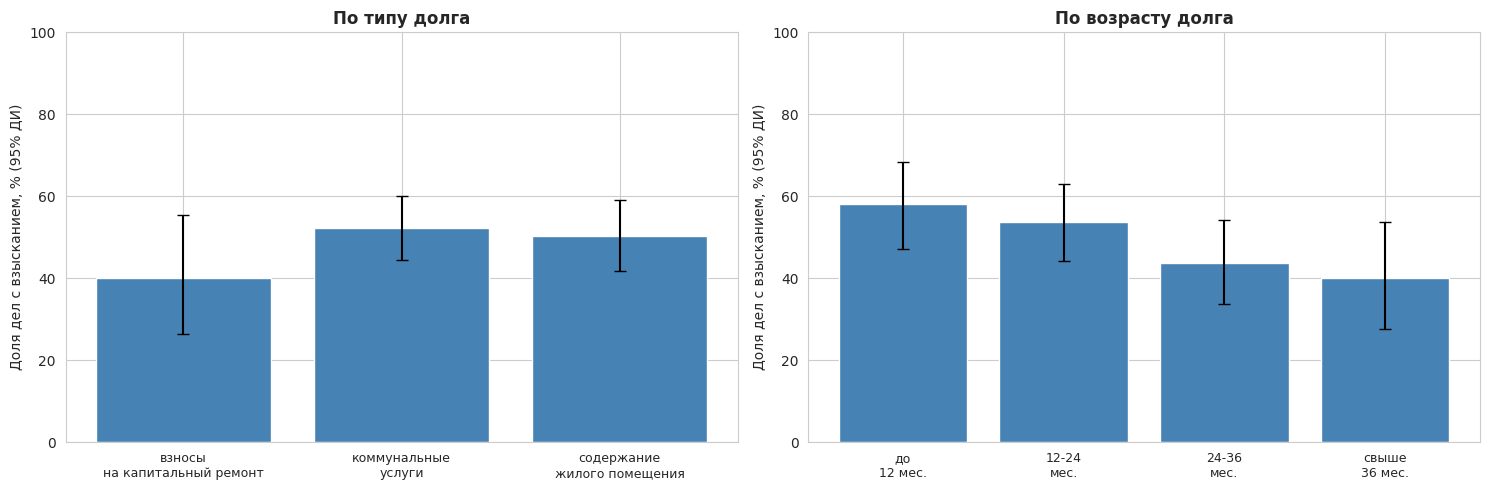

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, tab, title in [(axes[0], by_type, 'По типу долга'), (axes[1], by_age, 'По возрасту долга')]:
    x = np.arange(len(tab))
    ax.bar(x, tab['доля_дел_с_взысканием_%'], color='steelblue', edgecolor='white')
    ax.errorbar(x, tab['доля_дел_с_взысканием_%'],
                yerr=[tab['доля_дел_с_взысканием_%'] - tab['ДИ_нижн_%'], tab['ДИ_верх_%'] - tab['доля_дел_с_взысканием_%']],
                fmt='none', ecolor='black', capsize=4)
    ax.set_xticks(x); ax.set_xticklabels([str(i).replace(' ', '\n', 1) for i in tab.index], fontsize=9)
    ax.set_ylim(0, 100); ax.set_ylabel('Доля дел с взысканием, % (95% ДИ)')
    ax.set_title(title, fontweight='bold')
plt.tight_layout(); plt.show()

## 7. Сроки взыскания

,дел,медиана_дней,q25,q75
путь,,,,
1. оплата после претензии,59,22.00,17.00,25.50
2. через судебный приказ,198,224.00,167.50,294.00
3. через иск,63,294.00,226.00,365.00


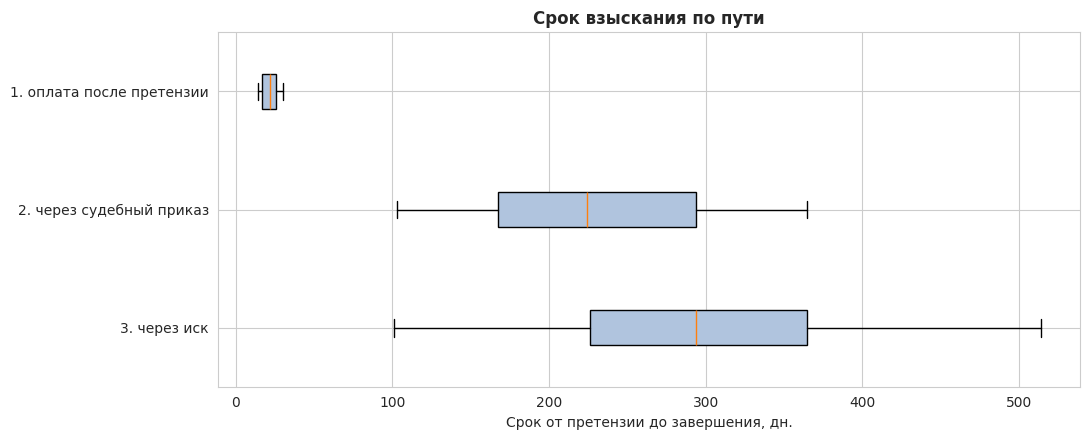

In [9]:
def path_of(r):
    if r['оплачено_после_претензии'] == 1:
        return '1. оплата после претензии'
    if r['иск_подан'] == 1:
        return '3. через иск'
    if r['приказ_выдан'] == 1:
        return '2. через судебный приказ'
    return '4. прочее'

df['путь'] = df.apply(path_of, axis=1)
timing = df.groupby('путь').agg(дел=('срок_дней', 'size'),
                                медиана_дней=('срок_дней', 'median'),
                                q25=('срок_дней', lambda s: s.quantile(0.25)),
                                q75=('срок_дней', lambda s: s.quantile(0.75)))
display(timing)

fig, ax = plt.subplots(figsize=(11, 4.5))
order = sorted(df['путь'].unique())
ax.boxplot([df.loc[df['путь'] == p, 'срок_дней'] for p in order], orientation='horizontal',
           tick_labels=order, patch_artist=True, boxprops=dict(facecolor='lightsteelblue'))
ax.invert_yaxis()
ax.set_xlabel('Срок от претензии до завершения, дн.'); ax.set_ylabel('')
ax.set_title('Срок взыскания по пути', fontweight='bold')
plt.tight_layout(); plt.show()

## 8. Срок исковой давности
Срок исковой давности - 3 года (ст. 196 ГК РФ), он исчисляется по каждому ежемесячному платежу отдельно. Здесь использована **упрощённая оценка**: часть долга старше 36 месяцев считается утраченной пропорционально возрасту долга. На реальном реестре расчёт нужно выполнять по помесячной разбивке.

,значение
дел в выборке,320.00
дел с возрастом долга от 30 мес.,106.00
"доля таких дел, %",33.10
"утрачено по давности, руб.","161,020.00"
"доля от заявленных сумм, %",1.30


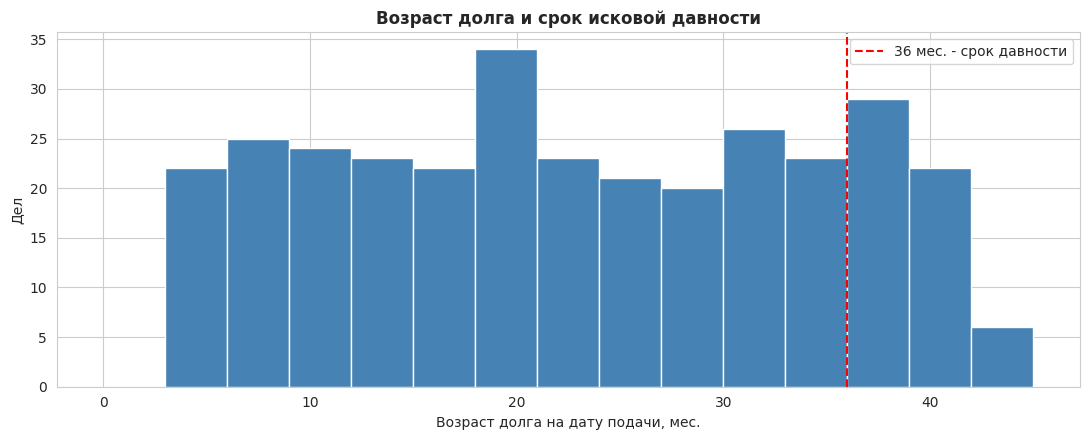

In [10]:
lim = ASSUMPTIONS['limitation_months']
at_risk = df[df['возраст_долга_мес'] >= lim - 6]       # дела, где до истечения давности остаётся до 6 мес. или она истекла
summary = pd.Series({
    'дел в выборке': len(df),
    f'дел с возрастом долга от {lim - 6} мес.': len(at_risk),
    'доля таких дел, %': round(len(at_risk) / len(df) * 100, 1),
    'утрачено по давности, руб.': round(df['утрачено_по_давности'].sum()),
    'доля от заявленных сумм, %': round(df['утрачено_по_давности'].sum() / df['сумма_долга'].sum() * 100, 1),
}, name='значение')
display(summary.to_frame())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(df['возраст_долга_мес'], bins=range(0, 46, 3), color='steelblue', edgecolor='white')
ax.axvline(lim, color='red', linestyle='--', label=f'{lim} мес. - срок давности')
ax.set_xlabel('Возраст долга на дату подачи, мес.'); ax.set_ylabel('Дел')
ax.set_title('Возраст долга и срок исковой давности', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.show()

## 9. Очерёдность подачи: ожидаемая отдача
Если возможности ограничены, дела целесообразно подавать в порядке убывания ожидаемой отдачи:  
`ожидаемая отдача = сумма × доля успешных дел в группе × средняя доля взысканного`.  
Группа - тип долга и возрастная группа; если в группе менее 10 дел, используется показатель по типу долга. Расчёт иллюстрируется на условном портфеле из восьми долгов.

In [11]:
succ = df[df['взыскано_флаг'] == 1]
grp = df.groupby(['тип_долга', 'возрастная_группа'], observed=True)['взыскано_флаг'].agg(['sum', 'size'])
typ = df.groupby('тип_долга')['взыскано_флаг'].agg(['sum', 'size'])
share_rec = (succ['взыскано'] / succ['сумма_к_взысканию']).mean()

def expected_recovery(debt_type, age_months, amount):
    age_group = pd.cut([age_months], [0, 12, 24, 36, 120],
                       labels=['до 12 мес.', '12-24 мес.', '24-36 мес.', 'свыше 36 мес.'])[0]
    eff = amount * (1 - max(0, age_months - lim) / age_months)
    key = (debt_type, age_group)
    if key in grp.index and grp.loc[key, 'size'] >= 10:
        p = grp.loc[key, 'sum'] / grp.loc[key, 'size']
    else:
        p = typ.loc[debt_type, 'sum'] / typ.loc[debt_type, 'size']
    return round(eff * p * share_rec)

portfolio = pd.DataFrame([
    ('коммунальные услуги', 8, 42_000), ('коммунальные услуги', 30, 95_000),
    ('содержание жилого помещения', 14, 60_000), ('содержание жилого помещения', 38, 80_000),
    ('взносы на капитальный ремонт', 6, 25_000), ('взносы на капитальный ремонт', 26, 70_000),
    ('коммунальные услуги', 20, 15_000), ('содержание жилого помещения', 5, 90_000),
], columns=['тип_долга', 'возраст_долга_мес', 'сумма_долга'])
portfolio['ожидаемая_отдача_руб'] = [expected_recovery(*r) for r in portfolio.itertuples(index=False)]
portfolio.sort_values('ожидаемая_отдача_руб', ascending=False).reset_index(drop=True)

,тип_долга,возраст_долга_мес,сумма_долга,ожидаемая_отдача_руб
0,коммунальные услуги,30,95000,39363
1,содержание жилого помещения,5,90000,38678
2,содержание жилого помещения,14,60000,28490
3,коммунальные услуги,8,42000,19820
4,содержание жилого помещения,38,80000,16350
5,взносы на капитальный ремонт,6,25000,14708
6,взносы на капитальный ремонт,26,70000,8090
7,коммунальные услуги,20,15000,6472


## 10. SQL-запросы к тем же данным
Те же показатели рассчитываются средствами SQL (SQLite). Запросы пригодны для выгрузки из базы управляющей компании после замены имени таблицы.

In [12]:
con = sqlite3.connect(':memory:')
df.drop(columns=['возрастная_группа']).to_sql('cases', con, index=False)
def q(sql):
    return pd.read_sql_query(sql, con)

print('1. Воронка по типам долга')
display(q('''
SELECT тип_долга,
       COUNT(*)                                            AS дел,
       SUM(оплачено_после_претензии)                       AS оплачено_после_претензии,
       SUM(приказ_выдан)                                   AS приказов,
       SUM(приказ_отменён)                                 AS отменено,
       SUM(на_исполнении)                                  AS на_исполнении,
       SUM(взыскано_флаг)                                  AS дел_с_взысканием
FROM cases GROUP BY тип_долга ORDER BY дел DESC'''))

print('2. Взыскиваемость по сумме по возрасту долга')
display(q('''
SELECT CASE WHEN возраст_долга_мес <= 12 THEN '1. до 12 мес.'
            WHEN возраст_долга_мес <= 24 THEN '2. 12-24 мес.'
            WHEN возраст_долга_мес <= 36 THEN '3. 24-36 мес.'
            ELSE '4. свыше 36 мес.' END                    AS возраст,
       COUNT(*)                                            AS дел,
       ROUND(SUM(взыскано) * 100.0 / SUM(сумма_к_взысканию), 1) AS взыскиваемость_pct
FROM cases GROUP BY 1 ORDER BY 1'''))

print('3. Срок взыскания по пути (среднее, дн.)')
display(q('''
SELECT путь, COUNT(*) AS дел, ROUND(AVG(срок_дней), 0) AS средний_срок_дн
FROM cases GROUP BY путь ORDER BY путь'''))

print('4. Десять дел с наибольшими потерями по давности')
display(q('''
SELECT тип_долга, возраст_долга_мес, сумма_долга, ROUND(утрачено_по_давности) AS утрачено_руб
FROM cases WHERE утрачено_по_давности > 0
ORDER BY утрачено_по_давности DESC LIMIT 10'''))
con.close()

1. Воронка по типам долга


,тип_долга,дел,оплачено_после_претензии,приказов,отменено,на_исполнении,дел_с_взысканием
0,коммунальные услуги,155,34,113,19,115,81
1,содержание жилого помещения,125,20,96,16,100,63
2,взносы на капитальный ремонт,40,5,33,9,34,16


2. Взыскиваемость по сумме по возрасту долга


,возраст,дел,взыскиваемость_pct
0,1. до 12 мес.,79,44.90
1,2. 12-24 мес.,104,47.20
2,3. 24-36 мес.,87,33.60
3,4. свыше 36 мес.,50,30.20


3. Срок взыскания по пути (среднее, дн.)


,путь,дел,средний_срок_дн
0,1. оплата после претензии,59,22.00
1,2. через судебный приказ,198,230.00
2,3. через иск,63,298.00


4. Десять дел с наибольшими потерями по давности


,тип_долга,возраст_долга_мес,сумма_долга,утрачено_руб
0,коммунальные услуги,42,"100,000.00","14,286.00"
1,содержание жилого помещения,42,"96,900.00","13,843.00"
2,коммунальные услуги,41,"66,500.00","8,110.00"
3,коммунальные услуги,41,"56,800.00","6,927.00"
4,коммунальные услуги,41,"56,300.00","6,866.00"
5,коммунальные услуги,41,"52,300.00","6,378.00"
6,коммунальные услуги,40,"61,500.00","6,150.00"
7,коммунальные услуги,41,"47,900.00","5,841.00"
8,взносы на капитальный ремонт,42,"38,400.00","5,486.00"
9,коммунальные услуги,38,"98,500.00","5,184.00"


## 11. Выводы
Текст ниже формируется из рассчитанных значений, поэтому при замене данных он обновляется вместе с расчётом.

In [13]:
from IPython.display import Markdown
f = funnel.set_index('переход')['доля'] * 100
best_type = by_type['доля_дел_с_взысканием_%'].idxmax()
worst_type = by_type['доля_дел_с_взысканием_%'].idxmin()
old_mask = df['возрастная_группа'] == 'свыше 36 мес.'
old = df.loc[old_mask, 'взыскано'].sum() / df.loc[old_mask, 'сумма_к_взысканию'].sum() * 100
rest = df.loc[~old_mask, 'взыскано'].sum() / df.loc[~old_mask, 'сумма_к_взысканию'].sum() * 100
tm = timing['медиана_дней']
total_recov = df['взыскано'].sum() / df['сумма_к_взысканию'].sum() * 100
loss_share = df['утрачено_по_давности'].sum() / df['сумма_долга'].sum() * 100

note = ('> Данные смоделированы. Показатели отражают допущения раздела 2 и демонстрируют методику; '
        'они не являются статистикой взыскания.' if IS_SYNTHETIC else
        '> Показатели рассчитаны по обезличенному реестру.')

Markdown(f'''
{note}

1. **Воронка.** После претензии оплачивают {f.iloc[0]:.0f}% должников; судебные приказы отменяются в {f.iloc[2]:.0f}% случаев; по {f.iloc[4]:.0f}% дел, переданных на исполнение, что-либо взыскано.
2. **Результативность по типам.** Наибольшая доля дел с взысканием - «{best_type}» ({by_type.loc[best_type, 'доля_дел_с_взысканием_%']:.0f}%), наименьшая - «{worst_type}» ({by_type.loc[worst_type, 'доля_дел_с_взысканием_%']:.0f}%). Интервалы широкие, поэтому различия между типами требуют проверки на большей выборке.
3. **Возраст долга.** По долгам старше 36 месяцев взыскиваемость по сумме составляет {old:.0f}% против {rest:.0f}% по остальному портфелю; внутри группы до 36 месяцев различия существенно меньше.
4. **Сроки.** Медиана: {'; '.join(f'{k[3:]} - {v:.0f} дн.' for k, v in tm.items())}
5. **Давность.** По упрощённой оценке по давности утрачено {loss_share:.1f}% заявленных сумм; общая взыскиваемость по портфелю - {total_recov:.0f}%.

**Практический вывод для организации работы:** подавать заявления по старым долгам в первую очередь (до наступления срока давности), а очерёдность остальных дел определять по ожидаемой отдаче (раздел 9).
''')


> Данные смоделированы. Показатели отражают допущения раздела 2 и демонстрируют методику; они не являются статистикой взыскания.

1. **Воронка.** После претензии оплачивают 18% должников; судебные приказы отменяются в 18% случаев; по 41% дел, переданных на исполнение, что-либо взыскано.
2. **Результативность по типам.** Наибольшая доля дел с взысканием - «коммунальные услуги» (52%), наименьшая - «взносы на капитальный ремонт» (40%). Интервалы широкие, поэтому различия между типами требуют проверки на большей выборке.
3. **Возраст долга.** По долгам старше 36 месяцев взыскиваемость по сумме составляет 30% против 42% по остальному портфелю; внутри группы до 36 месяцев различия существенно меньше.
4. **Сроки.** Медиана: оплата после претензии - 22 дн.; через судебный приказ - 224 дн.; через иск - 294 дн.
5. **Давность.** По упрощённой оценке по давности утрачено 1.3% заявленных сумм; общая взыскиваемость по портфелю - 40%.

**Практический вывод для организации работы:** подавать заявления по старым долгам в первую очередь (до наступления срока давности), а очерёдность остальных дел определять по ожидаемой отдаче (раздел 9).


## 12. Ограничения и порядок применения к реальным данным

**Ограничения**
- Данные смоделированы: выводы раздела 11 отражают параметры раздела 2 и не могут цитироваться как рыночная статистика.
- Срок давности рассчитан упрощённо (без помесячной разбивки и без учёта перерывов, приостановления и иных обстоятельств).
- Не учитываются расходы на взыскание (госпошлина, представительские расходы), пени и штрафные санкции.
- Выводы по группам при малых выборках статистически неустойчивы, что отражено доверительными интервалами.

**Применение к реальным данным**
1. Выгрузить реестр дел из учётной системы или Excel.
2. Обезличить: удалить ФИО, адреса, номера лицевых счетов.
3. Привести столбцы к схеме раздела 2 и сохранить как `data/claims_register.csv`.
4. Выполнить ноутбук целиком (`Kernel → Restart & Run All`): раздел 4 покажет ошибки учёта, остальные разделы пересчитаются.
5. Проверить выводы раздела 11 на достаточность выборки (не менее 30 дел в группе).